# 05 · Forecasting models and SHAP explanations

<a href="https://colab.research.google.com/github/FarhanRajputFelix/saans/blob/main/notebooks/05_models_shap.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. **Baselines** every model must beat: *persistence* (the next 24 hours will look like the last 24) and a *seasonal average* (the training mean for that city, month and hour).
2. **LightGBM regressors** for the next 24 hours and the 24 hours after that, plus 10th and 90th percentile models for an uncertainty band.
3. A **LightGBM hazard classifier**: will the next 24-hour mean exceed AQI 300?
4. **SHAP** attributes every forecast to four driver groups: recent pollution, weather, upwind fires and calendar.

**Split by time, never at random.** Training uses every hour up to 28 Sep 2024 (smog seasons 2020-23 plus the months between); the 2023-24 season is held aside inside it for early stopping. **Test 1** is the record 2024-25 season. **Test 2** is the 2025-26 season, including **Faisalabad and Multan, which the model has never seen**. A random split would leak tomorrow's air into training through the overlapping 24-hour windows.

**Setup.** Runs the same way locally and in Google Colab. In Colab it clones the repo (which includes the cleaned data) and reads API keys from Colab's *Secrets* panel (key icon on the left).

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules:
    if not os.path.exists("/content/saans"):
        subprocess.run(["git", "clone", "-q", "https://github.com/FarhanRajputFelix/saans.git", "/content/saans"], check=True)
    os.chdir("/content/saans")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm", "shap", "python-dotenv"], check=True)
    from google.colab import userdata
    for k in ["OPENAQ_API_KEY", "FIRMS_MAP_KEY", "GEMINI_API_KEY", "GROQ_API_KEY"]:
        try:
            os.environ[k] = userdata.get(k)
        except Exception:
            pass
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # work from the repo root so `saans` and `data/` resolve
sys.path.insert(0, os.getcwd())

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap

from saans.config import CITIES, PROCESSED, REPORTS, ROOT
from saans.aqi import HAZARDOUS_PM25, pm25_to_aqi, risk_level
from saans import viz

viz.use_style()
pd.set_option("display.width", 170)
FIG = REPORTS / "figures"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

feat = pd.read_parquet(PROCESSED / "features.parquet")
meta = json.loads((PROCESSED / "feature_groups.json").read_text())
GROUPS = meta["groups"]
FEATURES = sum(GROUPS.values(), [])
GROUP_OF = {f: g for g, fs in GROUPS.items() for f in fs}

t = feat.time_utc
TRAIN_END = pd.Timestamp("2024-09-28", tz="UTC")
VALID = (t >= "2023-10-01") & (t < "2024-02-01")
train_all = feat[(t < TRAIN_END) & feat.target_24h.notna() & feat.target_48h.notna() & feat.pm25_24h.notna()]
fit_part, valid_part = train_all[~VALID.loc[train_all.index]], train_all[VALID.loc[train_all.index]]
test = {"2024-25 season": feat[(t >= "2024-10-01") & (t < "2025-02-01")],
        "2025-26 season": feat[(t >= "2025-10-01") & (t < "2026-02-01")]}
print(f"train {len(train_all):,} rows ({len(valid_part):,} of them used for early stopping), cities: {sorted(train_all.city.unique())}")
for k, v in test.items():
    print(f"{k}: {int(v.target_24h.notna().sum()):,} rows with a target, cities: {sorted(v[v.target_24h.notna()].city.unique())}")

train 78,203 rows (8,457 of them used for early stopping), cities: ['islamabad', 'karachi', 'lahore']
2024-25 season: 7,652 rows with a target, cities: ['islamabad', 'karachi', 'lahore']
2025-26 season: 14,564 rows with a target, cities: ['faisalabad', 'islamabad', 'karachi', 'lahore', 'multan']


## Train the regressors: predict the *change*, not the level

A first version predicted the PM2.5 level directly. It barely beat persistence and badly under-forecast the record days: on 6 Nov 2024 it said 283 ug/m3 when the truth was 510. Tree models cannot predict outside the range they were trained on, and the 2024 season broke records.

So each model predicts the **change** from the last 24-hour mean, and the forecast is *last 24 h + predicted change*. When the air is already at 400, the model only has to judge whether it gets better or worse, and extremes are no longer cut off. This also cancels a constant offset between sensor networks (Lahore's data source changed when the US monitor feed stopped).

Early stopping on the 2023-24 season picks the number of trees; the final model is then refit on all training rows with that number.

In [3]:
PARAMS = dict(learning_rate=0.03, num_leaves=63, min_child_samples=50, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=1.0, n_estimators=3000, verbose=-1)

class ChangeModel:
    """LightGBM on (target - last 24 h mean); predictions are returned as levels."""
    def __init__(self, booster_model, n_trees):
        self.model, self.n_trees = booster_model, n_trees
    def predict(self, X):
        return X["pm25_24h"].to_numpy() + self.model.predict(X[FEATURES])

def fit(target, objective="regression", alpha=None):
    p = dict(PARAMS, objective=objective, **({"alpha": alpha} if alpha else {}))
    y_fit, y_val = fit_part[target] - fit_part.pm25_24h, valid_part[target] - valid_part.pm25_24h
    probe = lgb.LGBMRegressor(**p).fit(fit_part[FEATURES], y_fit, eval_X=valid_part[FEATURES], eval_y=y_val,
                                       callbacks=[lgb.early_stopping(100, verbose=False)])
    n = max(probe.best_iteration_, 50)
    final = lgb.LGBMRegressor(**dict(p, n_estimators=n)).fit(train_all[FEATURES], train_all[target] - train_all.pm25_24h)
    return ChangeModel(final, n)

reg24, reg48 = fit("target_24h"), fit("target_48h")
q10, q90 = fit("target_24h", "quantile", 0.1), fit("target_24h", "quantile", 0.9)
print(f"trees: 24 h model {reg24.n_trees}, 48 h model {reg48.n_trees}")

trees: 24 h model 114, 48 h model 116


## Evaluate against the baselines

Scored only on hours where the real 24-hour mean exists (test seasons are never interpolated). **Skill** = 1 - MAE(model) / MAE(persistence): 0 means no better than persistence, positive is better.

In [4]:
seasonal = train_all.assign(month=train_all.time_pkt.dt.month, hour=train_all.time_pkt.dt.hour)
seas_city = seasonal.groupby(["city", "month", "hour"]).target_24h.mean()
seas_all = seasonal.groupby(["month", "hour"]).target_24h.mean()

def seasonal_pred(df):
    key = pd.MultiIndex.from_arrays([df.city, df.time_pkt.dt.month, df.time_pkt.dt.hour])
    own = seas_city.reindex(key).to_numpy()
    pooled = seas_all.reindex(pd.MultiIndex.from_arrays([df.time_pkt.dt.month, df.time_pkt.dt.hour])).to_numpy()
    return np.where(np.isnan(own), pooled, own)  # unseen cities fall back to the pooled average

rows, preds = [], []
for season, df in test.items():
    for horizon, model, target in [("24 h", reg24, "target_24h"), ("48 h", reg48, "target_48h")]:
        d = df[df[target].notna() & df.pm25_24h.notna()].copy()
        d["model"] = model.predict(d)
        d["persistence"] = d.pm25_24h
        d["seasonal"] = seasonal_pred(d)
        for city, c in d.groupby("city"):
            row = {"season": season, "horizon": horizon, "city": CITIES[city].name,
                   "unseen_city": city not in set(train_all.city), "hours": len(c),
                   "mean_pm25": round(c[target].mean(), 0)}
            for name in ["model", "persistence", "seasonal"]:
                err = c[name] - c[target]
                row[f"MAE_{name}"] = round(err.abs().mean(), 1)
                row[f"RMSE_{name}"] = round(np.sqrt((err ** 2).mean()), 1)
            row["skill_vs_persistence"] = round(1 - row["MAE_model"] / row["MAE_persistence"], 3)
            rows.append(row)
        if horizon == "24 h":
            preds.append(d.assign(season=season))
evaluation = pd.DataFrame(rows)
evaluation.to_csv(REPORTS / "evaluation_regression.csv", index=False)
evaluation[["season", "horizon", "city", "unseen_city", "hours", "mean_pm25", "MAE_model", "MAE_persistence",
            "MAE_seasonal", "RMSE_model", "RMSE_persistence", "skill_vs_persistence"]]

,season,horizon,city,unseen_city,hours,mean_pm25,MAE_model,MAE_persistence,MAE_seasonal,RMSE_model,RMSE_persistence,skill_vs_persistence
0,2024-25 season,24 h,Islamabad,False,2952,89.0,14.7,16.5,25.7,20.4,23.7,0.109
1,2024-25 season,24 h,Karachi,False,1594,64.0,16.0,16.0,31.5,20.6,22.4,0.000
2,2024-25 season,24 h,Lahore,False,2952,235.0,47.9,57.9,79.7,69.5,83.4,0.173
3,2024-25 season,48 h,Islamabad,False,2952,90.0,19.4,23.0,25.7,26.3,31.5,0.157
4,2024-25 season,48 h,Karachi,False,1507,64.0,23.2,21.6,30.8,29.4,28.3,-0.074
5,2024-25 season,48 h,Lahore,False,2952,236.0,64.2,76.8,79.2,88.6,103.7,0.164
6,2025-26 season,24 h,Faisalabad,True,2886,219.0,33.3,38.7,99.0,43.6,50.7,0.140
7,2025-26 season,24 h,Islamabad,False,2928,101.0,12.8,15.1,34.8,18.2,20.8,0.152
8,2025-26 season,24 h,Karachi,False,2886,71.0,16.7,16.0,25.5,21.8,23.2,-0.044
9,2025-26 season,24 h,Lahore,False,2902,143.0,31.4,22.5,102.7,41.0,31.3,-0.396


In [5]:
summary = evaluation.groupby(["season", "horizon"]).apply(
    lambda e: pd.Series({"MAE_model": np.average(e.MAE_model, weights=e.hours),
                         "MAE_persistence": np.average(e.MAE_persistence, weights=e.hours),
                         "MAE_seasonal": np.average(e.MAE_seasonal, weights=e.hours)}), include_groups=False).round(1)
summary["skill_vs_persistence"] = (1 - summary.MAE_model / summary.MAE_persistence).round(3)
summary

MAE_model  MAE_persistence  MAE_seasonal  skill_vs_persistence
season         horizon                                                                
2024-25 season 24 h          28.0             32.7          48.2                 0.144
               48 h          38.0             44.1          48.0                 0.138
2025-26 season 24 h          25.4             25.8          68.5                 0.016
               48 h          34.6             36.1          69.6                 0.042

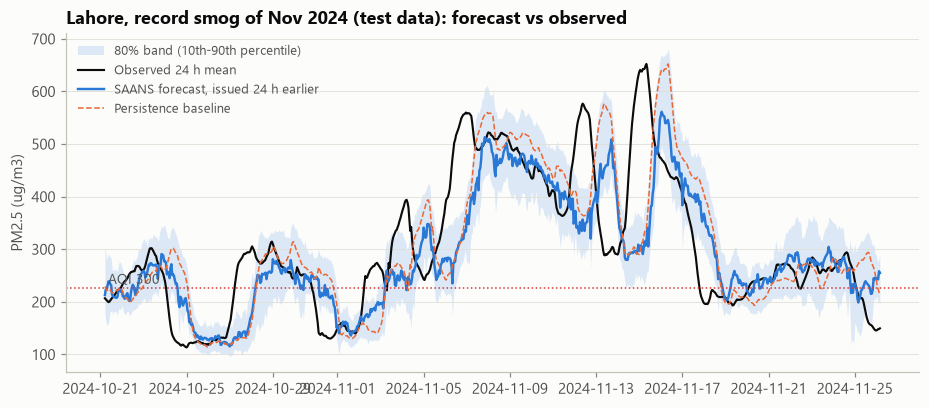

In [6]:
p = preds[0]
lh = p[(p.city == "lahore") & (p.time_utc >= "2024-10-20") & (p.time_utc < "2024-11-25")].sort_values("time_utc")
lh = lh.assign(lo=q10.predict(lh), hi=q90.predict(lh))
shift = pd.Timedelta(hours=24)  # plot each forecast at the time it is about
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(lh.time_pkt + shift, lh.lo, lh.hi, color=viz.SERIES[0], alpha=0.15, linewidth=0, label="80% band (10th-90th percentile)")
ax.plot(lh.time_pkt + shift, lh.target_24h, color=viz.INK, lw=1.4, label="Observed 24 h mean")
ax.plot(lh.time_pkt + shift, lh.model, color=viz.SERIES[0], lw=1.6, label="SAANS forecast, issued 24 h earlier")
ax.plot(lh.time_pkt + shift, lh.persistence, color=viz.SERIES[1], lw=1.0, ls="--", label="Persistence baseline")
ax.axhline(HAZARDOUS_PM25, color=viz.STATUS["critical"], lw=1, ls=":")
ax.annotate("AQI 300", (lh.time_pkt.min() + shift, HAZARDOUS_PM25), xytext=(2, 3), textcoords="offset points", fontsize=9, color=viz.INK_2)
ax.set(title="Lahore, record smog of Nov 2024 (test data): forecast vs observed", ylabel="PM2.5 (ug/m3)")
ax.legend(loc="upper left", fontsize=8.5)
fig.savefig(FIG / "forecast_lahore_nov2024.png", bbox_inches="tight")
plt.show()

## Hazard classifier: will the next 24 hours exceed AQI 300?

Measured as forecasters measure warnings:
* **Hit rate** (probability of detection): of the hazardous periods that happened, how many were warned?
* **False alarm ratio**: of the warnings issued, how many did not happen?
* **F1**: the balance of the two.

The decision threshold is chosen on the 2023-24 validation season (best F1), never on test data.

In [7]:
cls_params = dict(PARAMS, objective="binary", n_estimators=3000)
probe = lgb.LGBMClassifier(**cls_params).fit(fit_part[FEATURES], fit_part.hazard_24h,
                                            eval_X=valid_part[FEATURES], eval_y=valid_part.hazard_24h,
                                            callbacks=[lgb.early_stopping(100, verbose=False)])
p_valid = probe.predict_proba(valid_part[FEATURES])[:, 1]
def f1(y, yhat):
    tp, fp, fn = ((y == 1) & yhat).sum(), ((y == 0) & yhat).sum(), ((y == 1) & ~yhat).sum()
    return 2 * tp / max(2 * tp + fp + fn, 1)
grid = np.arange(0.1, 0.91, 0.05)
THRESHOLD = float(grid[np.argmax([f1(valid_part.hazard_24h.to_numpy(), p_valid >= th) for th in grid])])
clf = lgb.LGBMClassifier(**dict(cls_params, n_estimators=max(probe.best_iteration_, 50))).fit(train_all[FEATURES], train_all.hazard_24h)
print(f"decision threshold (from validation): {THRESHOLD:.2f}")

def warn_scores(y, yhat):
    tp, fp, fn = int(((y == 1) & yhat).sum()), int(((y == 0) & yhat).sum()), int(((y == 1) & ~yhat).sum())
    return {"hazardous_hours": int((y == 1).sum()), "hit_rate": round(tp / max(tp + fn, 1), 3),
            "false_alarm_ratio": round(fp / max(tp + fp, 1), 3), "F1": round(2 * tp / max(2 * tp + fp + fn, 1), 3)}

crows = []
for season, df in test.items():
    d = df[df.hazard_24h.notna() & df.pm25_24h.notna()]
    y = d.hazard_24h.to_numpy()
    crows.append({"season": season, "method": "SAANS classifier", **warn_scores(y, clf.predict_proba(d[FEATURES])[:, 1] >= THRESHOLD)})
    crows.append({"season": season, "method": "Persistence (last 24 h >= 225.5)", **warn_scores(y, d.pm25_24h.to_numpy() >= HAZARDOUS_PM25)})
cls_eval = pd.DataFrame(crows)
cls_eval.to_csv(REPORTS / "evaluation_classifier.csv", index=False)
cls_eval

decision threshold (from validation): 0.25


,season,method,hazardous_hours,hit_rate,false_alarm_ratio,F1
0,2024-25 season,SAANS classifier,1332,0.919,0.332,0.774
1,2024-25 season,Persistence (last 24 h >= 225.5),1332,0.755,0.244,0.755
2,2025-26 season,SAANS classifier,2913,0.922,0.331,0.775
3,2025-26 season,Persistence (last 24 h >= 225.5),2913,0.761,0.233,0.764


## SHAP: why is tomorrow's forecast what it is?

SHAP splits each prediction into additive contributions, one per feature, in ug/m3. Our model predicts the *change* from the last 24 hours, so the full forecast decomposes as:

*forecast = typical level + (today's level - typical level) + average change + SHAP contribution of every feature*

Today's level counts toward **Recent pollution**. Summing the contributions inside each group gives the four drivers in the dashboard's "Why today?" panel, and they add up exactly to the forecast.

Attribution is **statistical, not chemical**: SHAP says what the model relied on, which reflects correlations in the data, not measured emission sources.

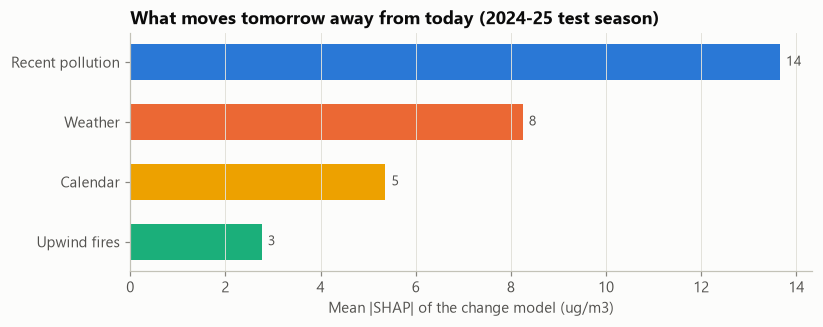

In [8]:
explainer = shap.TreeExplainer(reg24.model)
LEVEL_REF = float(train_all.pm25_24h.mean())          # typical 24 h level in training
BASE = LEVEL_REF + float(np.ravel(explainer.expected_value)[0])

def explain(X: pd.DataFrame) -> pd.DataFrame:
    """Per-feature contributions (ug/m3) that add up to forecast - BASE, today's level included."""
    c = pd.DataFrame(explainer.shap_values(X[FEATURES]), columns=FEATURES, index=X.index)
    c["pm25_24h"] += X["pm25_24h"] - LEVEL_REF
    return c

X24 = preds[0]
change_only = pd.DataFrame(explainer.shap_values(X24[FEATURES]), columns=FEATURES, index=X24.index)
contrib = explain(X24)
assert np.allclose(BASE + contrib.sum(axis=1), reg24.predict(X24), atol=0.01)  # explanations add up exactly
by_group = contrib.T.groupby(pd.Series(GROUP_OF)).sum().T
imp = change_only.T.groupby(pd.Series(GROUP_OF)).sum().T.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(imp.index, imp.values, color=[viz.DRIVER_COLORS[k] for k in imp.index], height=0.6)
for y, v in enumerate(imp.values):
    ax.annotate(f"{v:.0f}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=viz.INK_2, fontsize=9)
ax.set(title="What moves tomorrow away from today (2024-25 test season)", xlabel="Mean |SHAP| of the change model (ug/m3)")
ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False)
fig.savefig(FIG / "shap_groups.png", bbox_inches="tight")
plt.show()

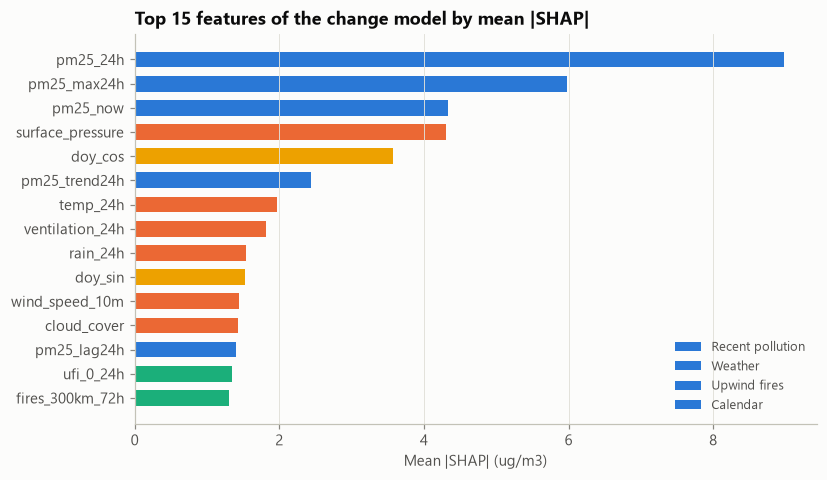

In [9]:
top = change_only.abs().mean().sort_values(ascending=False).head(15)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.index, top.values, color=[viz.DRIVER_COLORS[GROUP_OF[f]] for f in top.index], height=0.65)
for g, col in viz.DRIVER_COLORS.items():
    ax.barh([], [], color=col, label=g)
ax.set(title="Top 15 features of the change model by mean |SHAP|", xlabel="Mean |SHAP| (ug/m3)")
ax.grid(axis="x", visible=True); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", fontsize=8.5)
fig.savefig(FIG / "shap_top_features.png", bbox_inches="tight")
plt.show()

### One forecast explained: Lahore, 08:00 on 6 November 2024

The forecast issued that morning for the next 24 hours, the day the Punjab government closed schools across 18 districts:

typical level 70 + contributions +316 = forecast 386 ug/m3 (last 24 h: 472; observed next-24 h mean: 510, AQI 868)


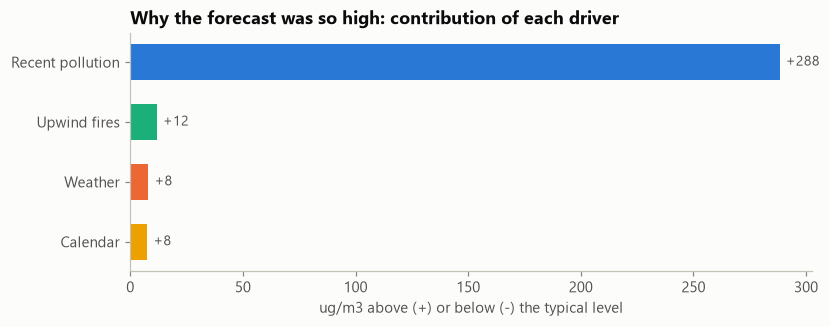

In [10]:
row = preds[0][(preds[0].city == "lahore") & (preds[0].time_pkt == pd.Timestamp("2024-11-06 08:00", tz="Asia/Karachi"))]
if len(row):
    i = row.index[0]
    parts = by_group.loc[i].sort_values()
    print(f"typical level {BASE:.0f} + contributions {parts.sum():+.0f} = forecast {BASE + parts.sum():.0f} ug/m3 "
          f"(last 24 h: {row.pm25_24h.iloc[0]:.0f}; observed next-24 h mean: {row.target_24h.iloc[0]:.0f}, "
          f"AQI {pm25_to_aqi(row.target_24h.iloc[0]):.0f})")
    fig, ax = plt.subplots(figsize=(8, 2.8))
    ax.barh(parts.index, parts.values, color=[viz.DRIVER_COLORS[k] for k in parts.index], height=0.6)
    for y, v in enumerate(parts.values):
        ax.annotate(f"{v:+.0f}", (v, y), xytext=(4 if v >= 0 else -4, 0), textcoords="offset points",
                    ha="left" if v >= 0 else "right", va="center", color=viz.INK_2, fontsize=9)
    ax.axvline(0, color=viz.AXIS, lw=1)
    ax.set(title="Why the forecast was so high: contribution of each driver", xlabel="ug/m3 above (+) or below (-) the typical level")
    ax.grid(axis="y", visible=False)
    fig.savefig(FIG / "shap_lahore_2024-11-06.png", bbox_inches="tight")
    plt.show()

## What-if: fewer upwind crop fires

Scale every fire feature down by a percentage and forecast again. This is a model-based **estimate**, not a chemical simulation: it shows how much of the forecast the model ties to fires.

In [11]:
def what_if(X: pd.DataFrame, reduction: float) -> np.ndarray:
    X = X.copy()
    X[GROUPS["Upwind fires"]] *= (1 - reduction)
    return reg24.predict(X)

if len(row):
    levels = np.arange(0, 1.01, 0.1)
    vals = [float(what_if(row, r)[0]) for r in levels]
    print(pd.DataFrame({"fire_reduction": [f"{r:.0%}" for r in levels], "forecast_ug_m3": np.round(vals, 0)}).T.to_string(header=False))

fire_reduction     0%    10%    20%    30%    40%    50%    60%    70%    80%    90%   100%
forecast_ug_m3  386.0  386.0  386.0  386.0  386.0  386.0  386.0  375.0  376.0  376.0  340.0


## Save models and the dashboard data

The dashboard gets one forecast per city per day (issued at 08:00 Pakistan time) for both test seasons, with uncertainty, hazard probability, the four SHAP driver values, the top three features, and the what-if curve precomputed. It needs no model and no API key at run time.

In [12]:
for name, mdl in [("reg24_change", reg24.model), ("reg48_change", reg48.model), ("q10_change", q10.model),
                  ("q90_change", q90.model), ("hazard", clf)]:
    mdl.booster_.save_model(str(MODELS / f"{name}.txt"))
(MODELS / "model_card.json").write_text(json.dumps({
    "target": "change of the next 24 h mean from the last 24 h mean (forecast = pm25_24h + prediction)",
    "features": FEATURES, "groups": GROUPS, "hazard_threshold": THRESHOLD, "train_end": str(TRAIN_END),
    "trees_24h": reg24.n_trees, "trees_48h": reg48.n_trees, "level_ref": LEVEL_REF}, indent=1))

LABELS = json.loads((ROOT / "saans" / "feature_labels.json").read_text(encoding="utf-8"))
issue = pd.concat(test.values())
issue = issue[(issue.time_pkt.dt.hour == 8) & issue.pm25_24h.notna()].copy()
X = issue
issue["forecast_24h"] = reg24.predict(X)
issue["forecast_48h"] = reg48.predict(X)
issue["q10"], issue["q90"] = q10.predict(X), q90.predict(X)
issue["hazard_prob"] = clf.predict_proba(X[FEATURES])[:, 1]
sv_issue = explain(X)
issue["shap_base"] = BASE
for g_name, cols in GROUPS.items():
    issue[f"shap_{g_name}"] = sv_issue[cols].sum(axis=1)
issue["top_drivers"] = [json.dumps([{"feature": f, "label": LABELS.get(f, f), "group": GROUP_OF[f], "ug_m3": round(float(v), 1)}
                                    for f, v in sv_issue.loc[i].sort_values(ascending=False).head(3).items()])
                        for i in issue.index]
for r in np.arange(0, 1.01, 0.1):
    issue[f"whatif_{int(round(r * 100))}"] = what_if(X, r)
issue["risk_level"] = [risk_level(v)[0] for v in issue.forecast_24h]
issue["season"] = np.where(issue.time_utc < "2025-06-01", "2024-25", "2025-26")
cols = (["city", "season", "time_utc", "time_pkt", "pm25_24h", "target_24h", "target_48h", "forecast_24h", "forecast_48h", "q10", "q90",
         "hazard_prob", "risk_level", "shap_base"] + [f"shap_{g}" for g in GROUPS] + ["top_drivers"]
        + [c for c in issue.columns if c.startswith("whatif_")])
dash = issue[cols].reset_index(drop=True)
DASH = ROOT / "app" / "data"
DASH.mkdir(parents=True, exist_ok=True)
dash.to_parquet(DASH / "forecasts_daily.parquet", index=False)
hourly = pd.concat(test.values())[["city", "time_utc", "pm25"]].dropna()
hourly.to_parquet(DASH / "observed_hourly.parquet", index=False)
(DASH / "evaluation.json").write_text(json.dumps({"regression": summary.reset_index().to_dict("records"),
                                                  "classifier": cls_eval.to_dict("records")}, indent=1, default=str))
print(f"dashboard data: {len(dash):,} daily forecasts, {len(hourly):,} observed hours")
dash.groupby(["season", "city"]).size().unstack(fill_value=0)

dashboard data: 930 daily forecasts, 22,277 observed hours


city,faisalabad,islamabad,karachi,lahore,multan
season,,,,,
2024-25,0,123,72,123,0
2025-26,122,123,122,123,122
